In [1]:
# Reading in the initial data

import pandas as pd

weather = pd.read_csv('weather_measurement.csv', index_col="DATE")

In [2]:
weather

,STATION,NAME,ACMH,ACSH,AWND,DAPR,FMTM,FRGT,MDPR,PGTM,...,WT01,WT02,WT03,WT04,WT05,WT07,WT08,WT09,WT16,WT18
DATE,,,,,,,,,,,,,,,,,,,,,
1960-01-01,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1960-01-02,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN
1960-01-03,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1960-01-04,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1960-01-05,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-27,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,6.71,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-28,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,4.92,NaN,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-29,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,3.13,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# cleaning of the data

weather.isnull().sum() / weather.shape[0] # the percentage of null values

STATION    0.000000
NAME       0.000000
ACMH       0.685756
ACSH       0.685756
AWND       0.473679
DAPR       0.999570
FMTM       0.882239
FRGT       0.999892
MDPR       0.999570
PGTM       0.538581
PRCP       0.015218
SNOW       0.388073
SNWD       0.381406
TAVG       0.890466
TMAX       0.000591
TMIN       0.000753
TSUN       0.938108
WDF2       0.473625
WDF5       0.478572
WSF2       0.473571
WSF5       0.478572
WT01       0.772652
WT02       0.980319
WT03       0.992579
WT04       0.999785
WT05       0.998441
WT07       0.999892
WT08       0.821907
WT09       0.999892
WT16       0.894876
WT18       0.999839
dtype: float64

In [4]:
# choosing the most important columns
core_weather = weather[['PRCP', 'TMAX', 'TMIN', 'SNOW', 'SNWD']].copy()

In [5]:
core_weather.columns = ['precip','temp_max','temp_min','snow','snow_depth']

In [6]:
core_weather

,precip,temp_max,temp_min,snow,snow_depth
DATE,,,,,
1960-01-01,0.0,49.0,30.0,0.0,0.0
1960-01-02,0.0,49.0,29.0,0.0,0.0
1960-01-03,0.0,54.0,35.0,0.0,0.0
1960-01-04,0.0,54.0,36.0,0.0,0.0
1960-01-05,0.0,55.0,33.0,0.0,0.0
...,...,...,...,...,...
2026-10-27,0.0,65.0,48.0,NaN,NaN
2026-10-28,0.0,70.0,45.0,NaN,NaN
2026-10-29,0.0,68.0,47.0,NaN,NaN


In [7]:
core_weather.isnull().sum()/core_weather.shape[0]

precip        0.015218
temp_max      0.000591
temp_min      0.000753
snow          0.388073
snow_depth    0.381406
dtype: float64

In [8]:
core_weather['snow'].value_counts() # just 1 day snow

snow
0.0    11379
1.0        1
Name: count, dtype: int64

In [9]:
core_weather['snow_depth'].isnull().sum()

np.int64(7093)

In [10]:
del core_weather['snow']

In [11]:
core_weather['snow_depth'].value_counts()

snow_depth
0.0    11504
Name: count, dtype: int64

In [12]:
del core_weather['snow_depth']
# df.drop(['SNOW','SNWD'], axis=1, inplace=True)

In [13]:
core_weather.info()

<class 'pandas.DataFrame'>
Index: 18597 entries, 1960-01-01 to 2026-10-31
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   precip    18314 non-null  float64
 1   temp_max  18586 non-null  float64
 2   temp_min  18583 non-null  float64
dtypes: float64(3)
memory usage: 581.2+ KB


In [14]:
core_weather.describe()

,precip,temp_max,temp_min
count,18314.000000,18586.000000,18583.000000
mean,0.047410,65.841924,50.455201
std,0.188361,8.352896,6.748852
min,0.000000,38.000000,1.000000
25%,0.000000,60.000000,46.000000
50%,0.000000,65.000000,51.000000
75%,0.000000,71.000000,56.000000
max,5.010000,122.000000,69.000000


In [15]:
core_weather[pd.isnull(core_weather['precip'])]

,precip,temp_max,temp_min
DATE,,,
1983-10-29,NaN,67.0,57.0
1983-10-30,NaN,70.0,63.0
1983-10-31,NaN,69.0,61.0
1983-11-12,NaN,63.0,55.0
1983-11-13,NaN,60.0,50.0
...,...,...,...
2016-05-02,NaN,68.0,53.0
2016-05-08,NaN,67.0,56.0
2017-10-28,NaN,68.0,50.0


In [16]:
core_weather.loc['1983-10-20':'1983-11-05',:]

,precip,temp_max,temp_min
DATE,,,
1983-10-20,0.00,73.0,52.0
1983-10-21,0.00,70.0,50.0
1983-10-22,0.00,70.0,50.0
1983-10-23,0.00,69.0,60.0
1983-10-24,0.00,73.0,58.0
1983-10-25,0.00,75.0,53.0
1983-10-26,0.00,79.0,53.0
1983-10-27,0.00,82.0,56.0
1983-10-28,0.00,74.0,56.0


In [17]:
core_weather['precip'].value_counts()

precip
0.00    15161
0.01      459
0.02      211
0.03      132
0.05      109
        ...  
1.92        1
1.77        1
5.01        1
1.28        1
1.44        1
Name: count, Length: 180, dtype: int64

In [18]:
#core_weather['precip'] = core_weather['precip'].fillna(core_weather['precip'].mean())
core_weather['precip'] = core_weather['precip'].fillna(0)

In [19]:
core_weather.columns

Index(['precip', 'temp_max', 'temp_min'], dtype='str')

In [20]:
core_weather[pd.isnull(core_weather['temp_min'])]

,precip,temp_max,temp_min
DATE,,,
2004-11-20,0.0,NaN,NaN
2011-12-21,0.0,61.0,NaN
2011-12-22,0.0,62.0,NaN
2011-12-23,0.0,56.0,NaN
2011-12-24,0.0,55.0,NaN
2011-12-25,0.0,54.0,NaN
2013-06-16,0.0,NaN,NaN
2020-08-29,0.0,NaN,NaN
2020-09-08,0.0,NaN,NaN


In [21]:
core_weather['precip'].isnull().sum()

np.int64(0)

In [23]:
core_weather[['temp_max', 'temp_min']].isnull().sum()

temp_max    11
temp_min    14
dtype: int64

In [58]:
#core_weather['temp_min'] = core_weather['temp_min'].fillna(core_weather['temp_min'].mean())
core_weather = core_weather.fillna(0)

In [59]:
#core_weather['temp_max'] = core_weather['temp_max'].fillna(core_weather['temp_max'].mean())

In [60]:
core_weather.apply(pd.isnull).sum()/core_weather.shape[0]
# percentage of NaNs in every column

precip      0.0
temp_max    0.0
temp_min    0.0
target      0.0
dtype: float64

In [61]:
core_weather.dtypes

precip      float64
temp_max    float64
temp_min    float64
target      float64
dtype: object

In [62]:
core_weather.index

DatetimeIndex(['1960-01-01', '1960-01-02', '1960-01-03', '1960-01-04',
               '1960-01-05', '1960-01-06', '1960-01-07', '1960-01-08',
               '1960-01-09', '1960-01-10',
               ...
               '2026-10-21', '2026-10-22', '2026-10-23', '2026-10-24',
               '2026-10-25', '2026-10-26', '2026-10-27', '2026-10-28',
               '2026-10-29', '2026-10-30'],
              dtype='datetime64[us]', name='DATE', length=18596, freq=None)

In [63]:
core_weather.index.dtype

dtype('<M8[us]')

In [64]:
core_weather.index = pd.to_datetime(core_weather.index)

In [65]:
core_weather.index

DatetimeIndex(['1960-01-01', '1960-01-02', '1960-01-03', '1960-01-04',
               '1960-01-05', '1960-01-06', '1960-01-07', '1960-01-08',
               '1960-01-09', '1960-01-10',
               ...
               '2026-10-21', '2026-10-22', '2026-10-23', '2026-10-24',
               '2026-10-25', '2026-10-26', '2026-10-27', '2026-10-28',
               '2026-10-29', '2026-10-30'],
              dtype='datetime64[us]', name='DATE', length=18596, freq=None)

In [32]:
core_weather.index.year

Index([1960, 1960, 1960, 1960, 1960, 1960, 1960, 1960, 1960, 1960,
       ...
       2026, 2026, 2026, 2026, 2026, 2026, 2026, 2026, 2026, 2026],
      dtype='int32', name='DATE', length=18597)

In [66]:
core_weather.apply(lambda x: (x == 9999).sum())

precip      0
temp_max    0
temp_min    0
target      0
dtype: int64

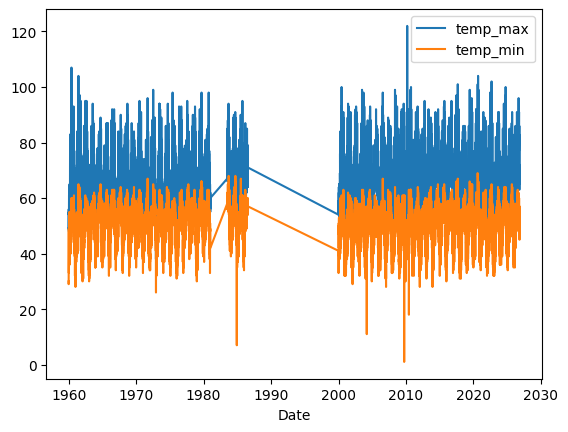

In [67]:
import matplotlib.pyplot as plt
plt.plot(core_weather[['temp_max', 'temp_min']])
plt.xlabel('Date')
plt.legend(['temp_max', 'temp_min'])

In [68]:
core_weather.index.year.value_counts().sort_index()

DATE
1960    366
1961    365
1962    365
1963    365
1964    366
1965    365
1966    365
1967    365
1968    366
1969    365
1970    365
1971    365
1972    366
1973    365
1974    365
1975    365
1976    366
1977    365
1978    365
1979    365
1980    366
1983    184
1984    366
1985    365
1986    212
2000    365
2001    365
2002    365
2003    365
2004    366
2005    365
2006    365
2007    365
2008    366
2009    365
2010    365
2011    365
2012    365
2013    365
2014    365
2015    365
2016    366
2017    365
2018    365
2019    365
2020    366
2021    365
2022    365
2023    365
2024    366
2025    365
2026    303
Name: count, dtype: int64

In [69]:
core_weather.columns

Index(['precip', 'temp_max', 'temp_min', 'target'], dtype='str')

Text(0.5, 0, 'Date')

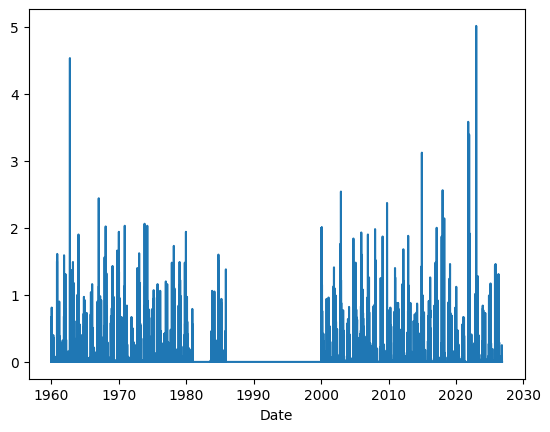

In [70]:
plt.plot(core_weather['precip'])
plt.xlabel('Date')

In [71]:
core_weather.groupby(core_weather.index.year).sum()

,precip,temp_max,temp_min,target
DATE,,,,
1960,14.01,24135.000000,17973.000000,24141.000000
1961,13.87,24202.000000,17819.000000,24197.000000
1962,22.47,23785.000000,17880.000000,23792.000000
1963,19.11,23470.000000,18237.000000,23465.000000
1964,16.83,23013.000000,18637.000000,23008.000000
1965,16.32,23181.000000,18715.000000,23183.000000
1966,13.11,23680.000000,18991.000000,23689.000000
1967,23.98,23433.000000,18668.000000,23426.000000
1968,17.19,23634.000000,18859.000000,23632.000000


<Axes: xlabel='DATE'>

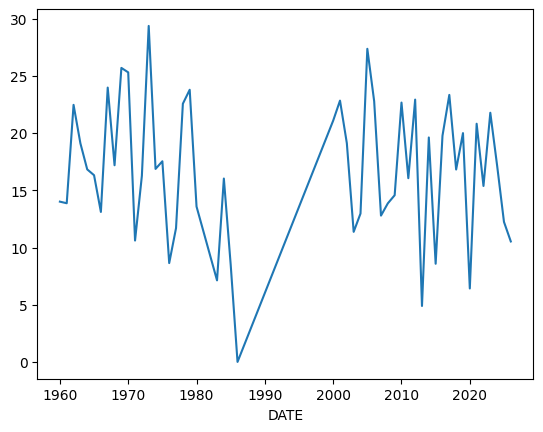

In [72]:
core_weather.groupby(core_weather.index.year)['precip'].sum().plot()

In [73]:
core_weather['target'] = core_weather.shift(-1)['temp_max']

In [74]:
core_weather

,precip,temp_max,temp_min,target
DATE,,,,
1960-01-01,0.0,49.0,30.0,49.0
1960-01-02,0.0,49.0,29.0,54.0
1960-01-03,0.0,54.0,35.0,54.0
1960-01-04,0.0,54.0,36.0,55.0
1960-01-05,0.0,55.0,33.0,53.0
...,...,...,...,...
2026-10-26,0.0,68.0,57.0,65.0
2026-10-27,0.0,65.0,48.0,70.0
2026-10-28,0.0,70.0,45.0,68.0


In [75]:
len(core_weather)

18596

In [76]:
core_weather = core_weather.iloc[:-1,:].copy()

In [96]:
core_weather.tail()

,precip,temp_max,temp_min,target
DATE,,,,
2026-10-25,0.0,72.0,47.0,68.0
2026-10-26,0.0,68.0,57.0,65.0
2026-10-27,0.0,65.0,48.0,70.0
2026-10-28,0.0,70.0,45.0,68.0
2026-10-29,0.0,68.0,47.0,66.0


In [78]:
from sklearn.linear_model import Ridge
reg = Ridge(alpha = 0.1)

In [79]:
predictors = ["precip","temp_max","temp_min"]

In [97]:
train = core_weather.loc[:"2020-12-31",:]
test = core_weather.loc["2021-01-01":,:]

In [98]:
train

,precip,temp_max,temp_min,target
DATE,,,,
1960-01-01,0.00,49.0,30.0,49.0
1960-01-02,0.00,49.0,29.0,54.0
1960-01-03,0.00,54.0,35.0,54.0
1960-01-04,0.00,54.0,36.0,55.0
1960-01-05,0.00,55.0,33.0,53.0
...,...,...,...,...
2020-12-27,0.00,63.0,44.0,61.0
2020-12-28,0.10,61.0,42.0,60.0
2020-12-29,0.00,60.0,39.0,56.0


In [99]:
test

,precip,temp_max,temp_min,target
DATE,,,,
2021-01-01,0.00,60.0,40.0,57.0
2021-01-02,0.14,57.0,51.0,56.0
2021-01-03,0.00,56.0,49.0,62.0
2021-01-04,0.36,62.0,46.0,59.0
2021-01-05,0.00,59.0,42.0,59.0
...,...,...,...,...
2026-10-25,0.00,72.0,47.0,68.0
2026-10-26,0.00,68.0,57.0,65.0
2026-10-27,0.00,65.0,48.0,70.0


In [100]:
model = reg.fit(train[predictors],train['target'])

In [101]:
model

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [102]:
predictions = model.predict(test[predictors])

In [104]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(test['target'], predictions)

3.3226070906836638

In [105]:
combined = pd.concat([test['target'],pd.Series(predictions, index=test.index)], axis=1)
combined.columns = ['actual','predictions']

In [106]:
combined

,actual,predictions
DATE,,
2021-01-01,57.0,59.810232
2021-01-02,56.0,59.308977
2021-01-03,62.0,58.538407
2021-01-04,59.0,61.533221
2021-01-05,59.0,59.447483
...,...,...
2026-10-25,68.0,69.717504
2026-10-26,65.0,68.624850
2026-10-27,70.0,64.849045


(20089.0, 20574.0)

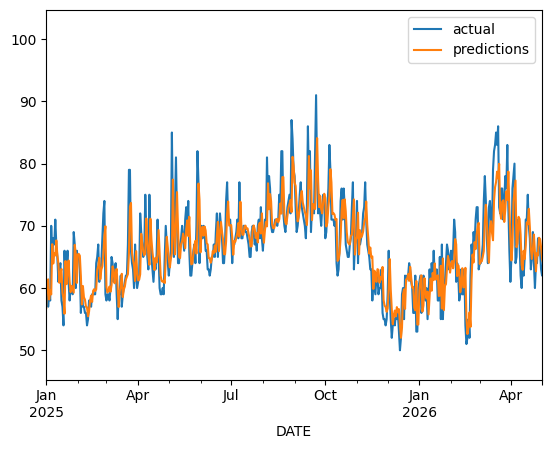

In [135]:
combined.plot()
plt.xlim('2025-01-01', '2026-05-01')

In [124]:
def create_predictions(predictors, core_weather, reg):
    train = core_weather.loc[:"2020-12-31"]
    test = core_weather.loc["2021-01-01":]

    reg.fit(train[predictors], train["target"])
    predictions = reg.predict(test[predictors])

    error = mean_absolute_error(test["target"], predictions)
    combined = pd.concat([test["target"],pd.Series(predictions, index=test.index)], axis=1)
    
    #combined = core_weather.concat([test["target"], pd.Series(predictions, index=test.index)], axis=1)
    combined.columns = ["actual", "predictions"]
    return error, combined

In [125]:
core_weather["month_max"] = core_weather["temp_max"].rolling(30).mean()

core_weather["month_day_max"] = core_weather["month_max"] / core_weather["temp_max"]

core_weather["max_min"] = core_weather["temp_max"] / core_weather["temp_min"] # ration between max & min temp

In [126]:
core_weather

,precip,temp_max,temp_min,target,month_max,month_day_max,max_min
DATE,,,,,,,
1960-01-31,0.00,59.0,46.0,62.0,NaN,NaN,1.282609
1960-02-01,0.81,62.0,51.0,59.0,NaN,NaN,1.215686
1960-02-02,0.00,59.0,43.0,59.0,NaN,NaN,1.372093
1960-02-03,0.20,59.0,47.0,60.0,NaN,NaN,1.255319
1960-02-04,0.16,60.0,42.0,60.0,NaN,NaN,1.428571
...,...,...,...,...,...,...,...
2026-10-25,0.00,72.0,47.0,68.0,74.700000,1.037500,1.531915
2026-10-26,0.00,68.0,57.0,65.0,74.633333,1.097549,1.192982
2026-10-27,0.00,65.0,48.0,70.0,74.633333,1.148205,1.354167


In [127]:
core_weather.columns

Index(['precip', 'temp_max', 'temp_min', 'target', 'month_max',
       'month_day_max', 'max_min'],
      dtype='str')

In [128]:
core_weather = core_weather.iloc[30:,:].copy()

In [129]:
predictors = ['precip', 'temp_max', 'temp_min', 'month_max', "month_day_max", "max_min"]

error, combined = create_predictions(predictors, core_weather, reg)

In [130]:
error

3.2632671149854975

In [153]:
reg.coef_

array([ -0.90063791,   0.39351173,   0.02969039,   0.34391215,
       -16.51209689,   0.04827501,   0.14279295,   0.08218248])

In [132]:
combined.index

DatetimeIndex(['2021-01-01', '2021-01-02', '2021-01-03', '2021-01-04',
               '2021-01-05', '2021-01-06', '2021-01-07', '2021-01-08',
               '2021-01-09', '2021-01-10',
               ...
               '2026-10-20', '2026-10-21', '2026-10-22', '2026-10-23',
               '2026-10-24', '2026-10-25', '2026-10-26', '2026-10-27',
               '2026-10-28', '2026-10-29'],
              dtype='datetime64[us]', name='DATE', length=2128, freq=None)

(20089.0, 20574.0)

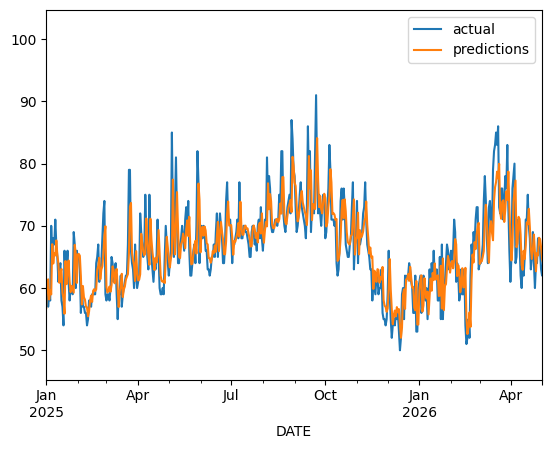

In [138]:
combined.plot()
plt.xlim('2025-01-01', '2026-05-01')

In [142]:
core_weather['monthly_avg'] = core_weather['temp_max'].groupby(core_weather.index.month).transform(lambda x: x.expanding(1).mean())

In [143]:
core_weather

,precip,temp_max,temp_min,target,month_max,month_day_max,max_min,monthly_avg
DATE,,,,,,,,
1960-03-01,0.00,55.0,43.0,58.0,59.866667,1.088485,1.279070,55.000000
1960-03-02,0.00,58.0,40.0,62.0,59.733333,1.029885,1.450000,56.500000
1960-03-03,0.00,62.0,47.0,62.0,59.833333,0.965054,1.319149,58.333333
1960-03-04,0.00,62.0,52.0,58.0,59.933333,0.966667,1.192308,59.250000
1960-03-05,0.13,58.0,54.0,59.0,59.866667,1.032184,1.074074,59.000000
...,...,...,...,...,...,...,...,...
2026-10-25,0.00,72.0,47.0,68.0,74.700000,1.037500,1.531915,70.805413
2026-10-26,0.00,68.0,57.0,65.0,74.633333,1.097549,1.192982,70.803633
2026-10-27,0.00,65.0,48.0,70.0,74.633333,1.148205,1.354167,70.799953


In [144]:
core_weather['day_of_year_avg'] = core_weather['temp_max'].groupby(core_weather.index.day_of_year).transform(lambda x: x.expanding(1).mean())

In [148]:
core_weather.columns

Index(['precip', 'temp_max', 'temp_min', 'target', 'month_max',
       'month_day_max', 'max_min', 'monthly_avg', 'day_of_year_avg'],
      dtype='str')

In [149]:
predictors = ['precip', 'temp_max', 'temp_min', 'month_max',
       'month_day_max', 'max_min', 'monthly_avg', 'day_of_year_avg']

In [150]:
error, combined = create_predictions(predictors, core_weather, reg)

In [151]:
error

3.2450252840011693

In [152]:
reg.coef_

array([ -0.90063791,   0.39351173,   0.02969039,   0.34391215,
       -16.51209689,   0.04827501,   0.14279295,   0.08218248])

In [154]:
core_weather.corr()['target']

precip            -0.207542
temp_max           0.820942
temp_min           0.593770
target             1.000000
month_max          0.687214
month_day_max     -0.421042
max_min            0.045769
monthly_avg        0.688631
day_of_year_avg    0.711109
Name: target, dtype: float64

In [155]:
combined['diff'] = (combined['actual'] - combined['predictions']).abs()

In [156]:
combined.sort_values('diff', ascending=False).head()

,actual,predictions,diff
DATE,,,
2022-06-20,98.0,76.766720,21.233280
2025-05-04,85.0,66.239161,18.760839
2024-09-29,90.0,72.321427,17.678573
2024-07-01,93.0,75.696767,17.303233
2026-07-20,88.0,71.322279,16.677721
